In [ ]:
def metrics(y_true, y_pred):
    """Common regression skill scores for continuous targets (usually MAR).

    mae  — mean absolute error (same units as the target; lower is better)
    corr — Pearson correlation between observations and predictions
    r2   — coefficient of determination (1 = perfect; can be negative)
    """
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "corr": float(np.corrcoef(y_true.ravel(), y_pred.ravel())[0, 1]),
        "r2": float(r2_score(y_true, y_pred)),
    }


def plot_pred_scatter(y_train, train_pred, y_test, test_pred, title):
    """Observed vs predicted scatter for train and test sites.

    The dashed line is the 1:1 relation: predictions near it are accurate.
    """
    tr = metrics(y_train, train_pred)
    te = metrics(y_test, test_pred)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(y_train, train_pred, s=8, alpha=0.35, label=f"train MAE={tr['mae']:.2f}, r={tr['corr']:.3f}")
    ax.scatter(y_test, test_pred, s=8, alpha=0.45, label=f"test MAE={te['mae']:.2f}, r={te['corr']:.3f}")
    lims = [
        min(y_train.min(), y_test.min(), train_pred.min(), test_pred.min()),
        max(y_train.max(), y_test.max(), train_pred.max(), test_pred.max()),
    ]
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlabel("Observed")
    ax.set_ylabel("Predicted")
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.set_aspect("equal", adjustable="box")
    plt.tight_layout()
    plt.show()
    return tr, te


## Load MAR observations and environmental predictors

We assemble paired **features** (environmental predictors) and **labels**
(observed mass accumulation rate, MAR) from Coastal Sediment (CS) and Deep Ocean
(DO) core compilations.

Features are **neural-network imputed values only** (113 dimensions): originally
missing predictors were filled by a separate imputation model, then the continuous
values are used here. Sites are split **75% train / 25% test**, stratified by MAR
deciles so high- and low-MAR regimes appear in both sets.


In [1]:
# Load CS + DO MAR sites with a stratified train/test split.
# Returns feature matrices, labels, and the mean/std used later to standardize
# global ocean grids the same way as the training data.
mar = load_mar_cs_do(preprocess_features_labels)

train_features = mar["train_features"]  # predictors at training sites
train_labels = mar["train_labels"]      # observed MAR at training sites
test_features = mar["test_features"]    # held-out predictors
test_labels = mar["test_labels"]        # held-out MAR (for skill scores)
X_mean, X_std = mar["x_mean"], mar["x_std"]  # standardization from the train set
world_dir = mar["world_dir"]            # folder of global ocean feature chunks

print(f"n_features={mar['n_features']} (NN-imputed values only)")
print(f"train={train_features.shape}, test={test_features.shape}")
print(f"CS path: {mar['paths']['CS']}")
print(f"DO path: {mar['paths']['DO']}")
print(f"world: {world_dir}")


n_features=113 (NN-imputed values only)
train=(9860, 113), test=(3288, 113)
CS path: data/interim/inputfeatures/CS_men_masked
DO path: data/interim/inputfeatures/DO_men_masked
world: data/interim/worldfeatures/World_Features_men_masked


## Fit ensemble tree models

We compare three tree-based regressors for MAR:

- **Random Forest** — bagged decision trees
- **XGBoost** — gradient-boosted trees
- **CatBoost** — ordered-boosting trees

The number of trees (`n_estimators`) for each model was selected by a held-out
hyperparameter search (700 / 1000 / 1000). Set `run_hyperparameter_search = True`
below to re-sweep those grids instead of using the selected counts.

> **Note on displayed outputs.** Cell outputs (training logs, learning curves, scatter plots, and maps) are taken from the archived hyperparameter-search run of **this same architecture**, not from a fresh execution of the cells above. Metrics therefore match the selected configuration; cosmetic plot styling may differ slightly from what `plot_pred_scatter` would draw if re-run locally.


Random Forest with 700 trees
Train MAE: 8.1470
Train Correlation: 0.9857
Train R2: 0.9715
Test MAE: 19.5047
Test Correlation: 0.9297
Test R2: 0.8642


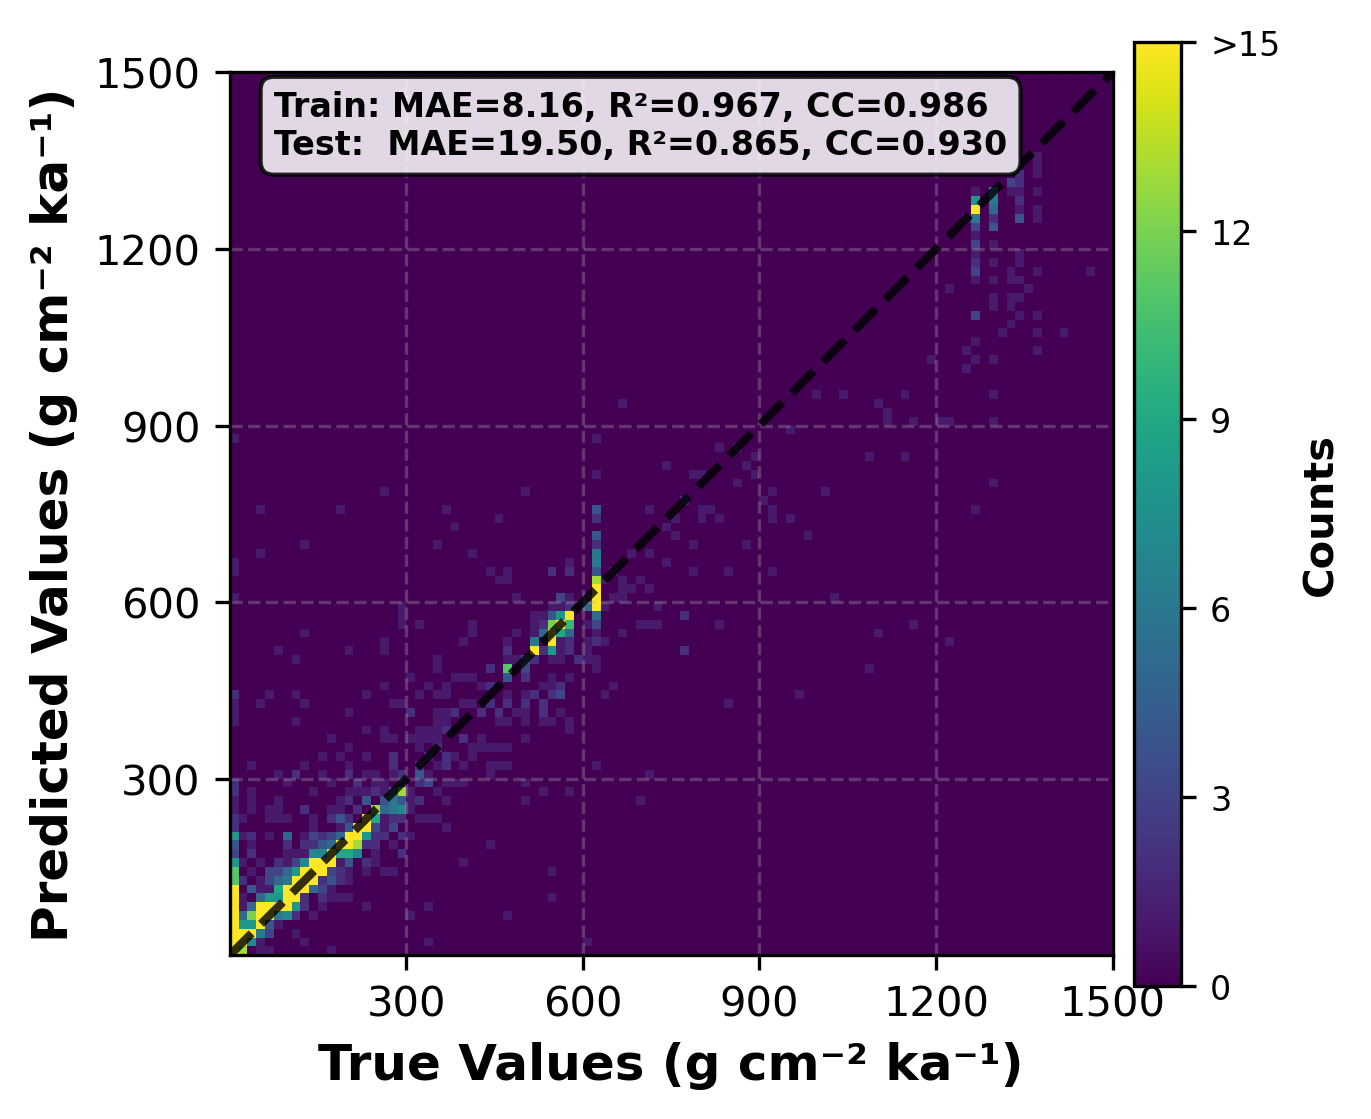

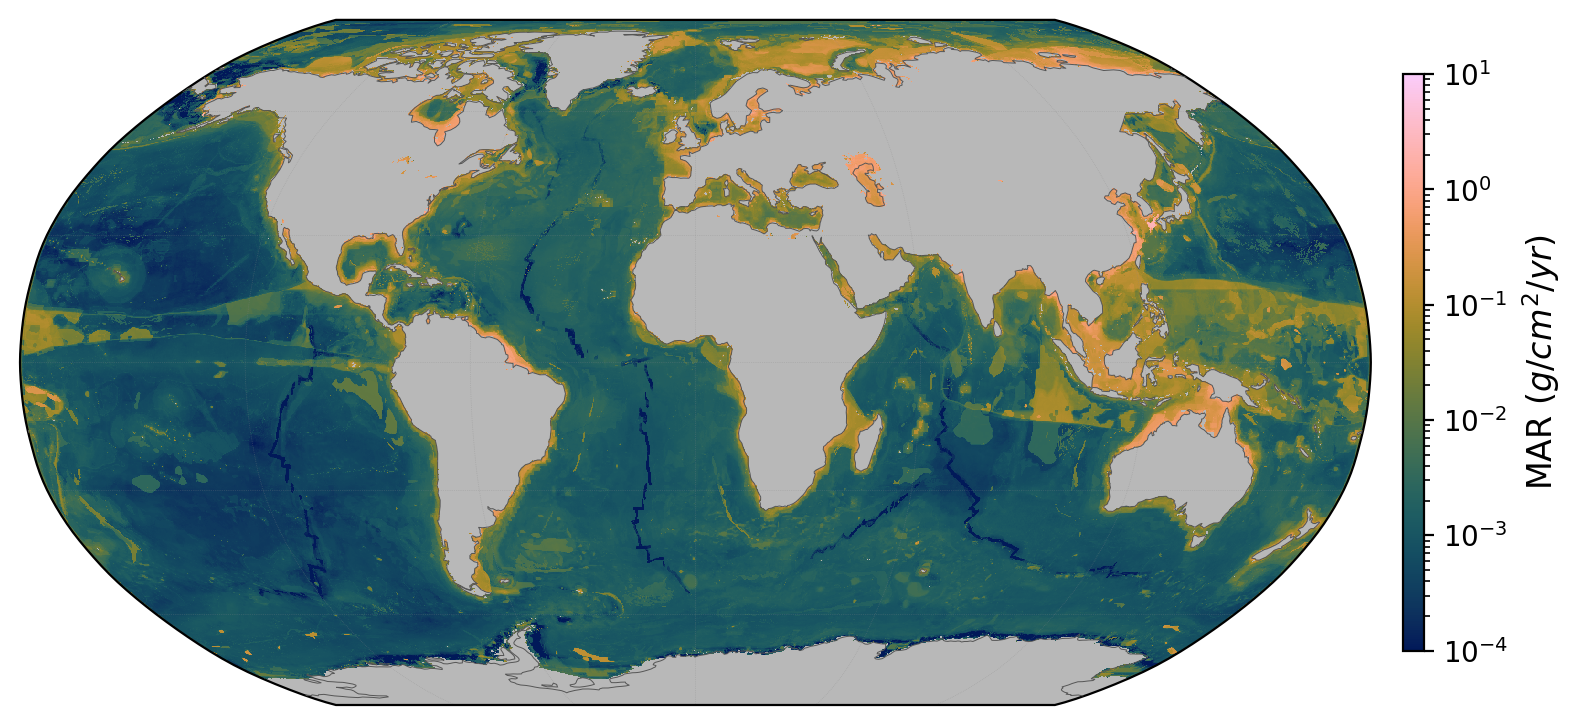

Finished Random Forest (n_estimators=700)


XGBoost with 1000 trees
Train MAE: 13.6090
Train Correlation: 0.9919
Train R2: 0.9839
Test MAE: 24.5308
Test Correlation: 0.9038
Test R2: 0.8169


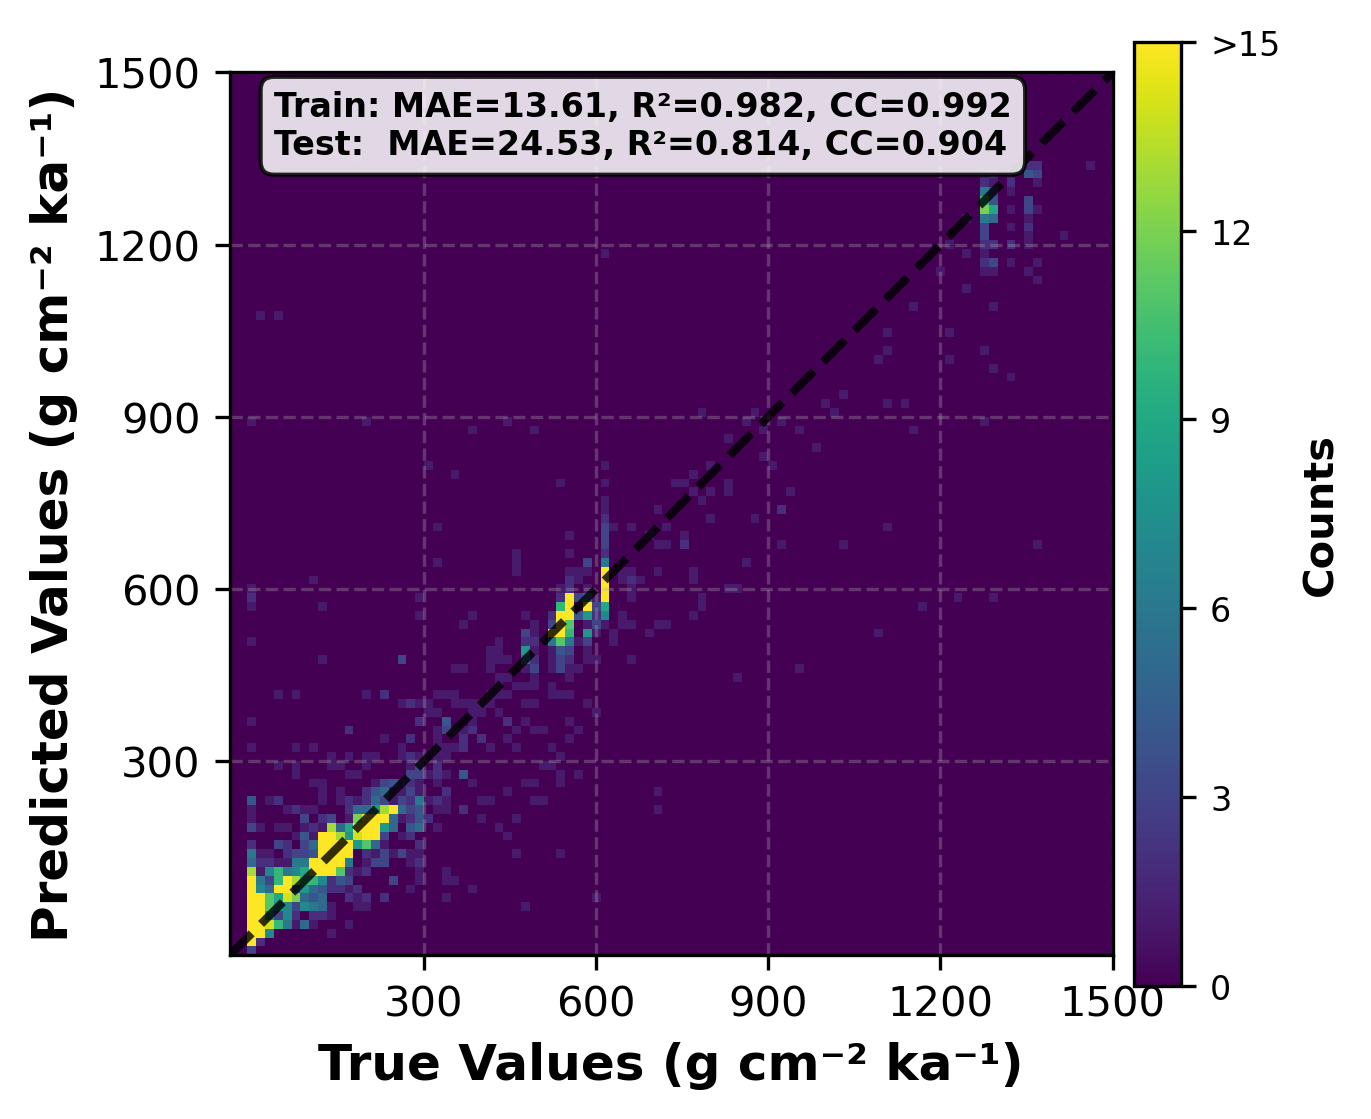

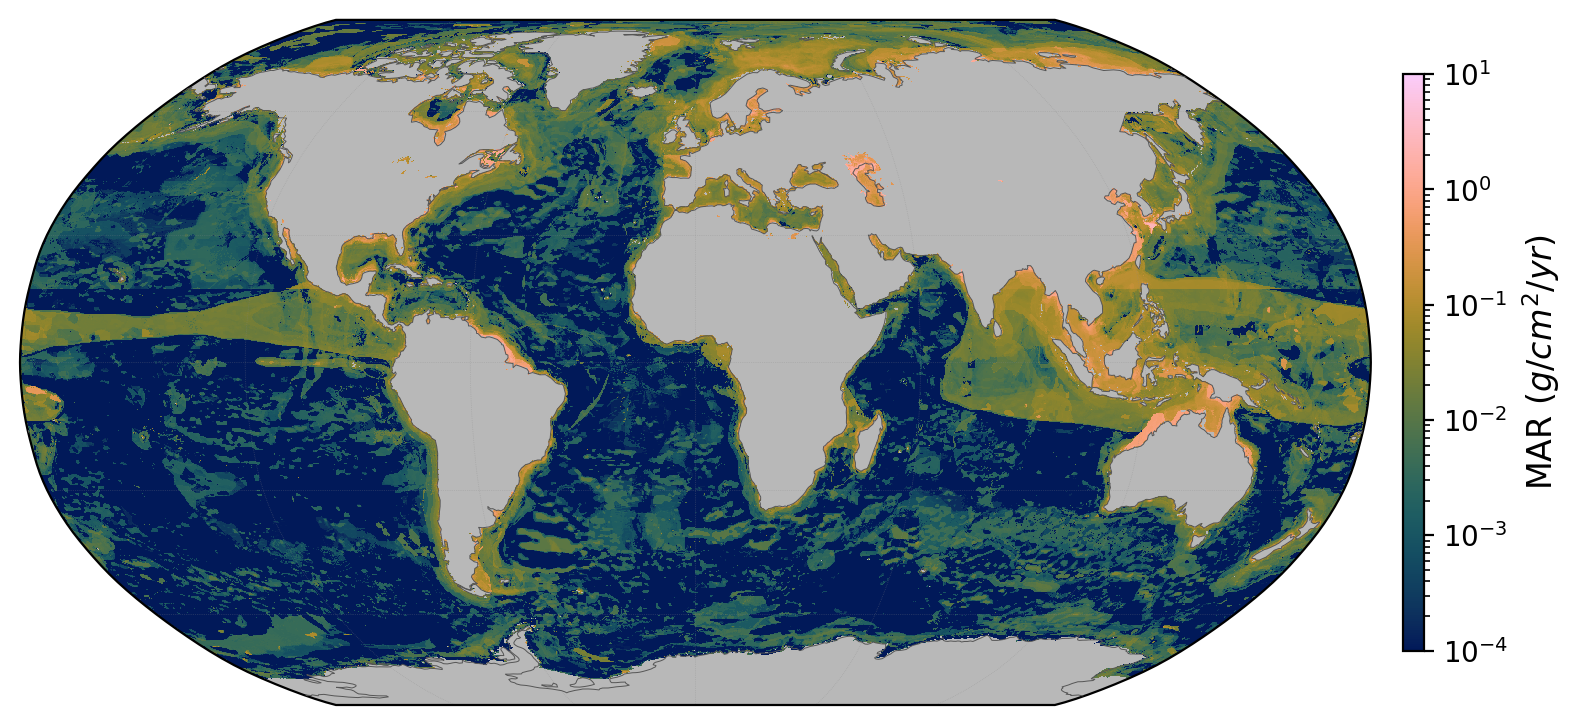

Finished XGBoost (n_estimators=1000)


CatBoost with 1000 trees
Train MAE: 31.0959
Train Correlation: 0.9484
Train R2: 0.8995
Test MAE: 34.2517
Test Correlation: 0.9048
Test R2: 0.8186


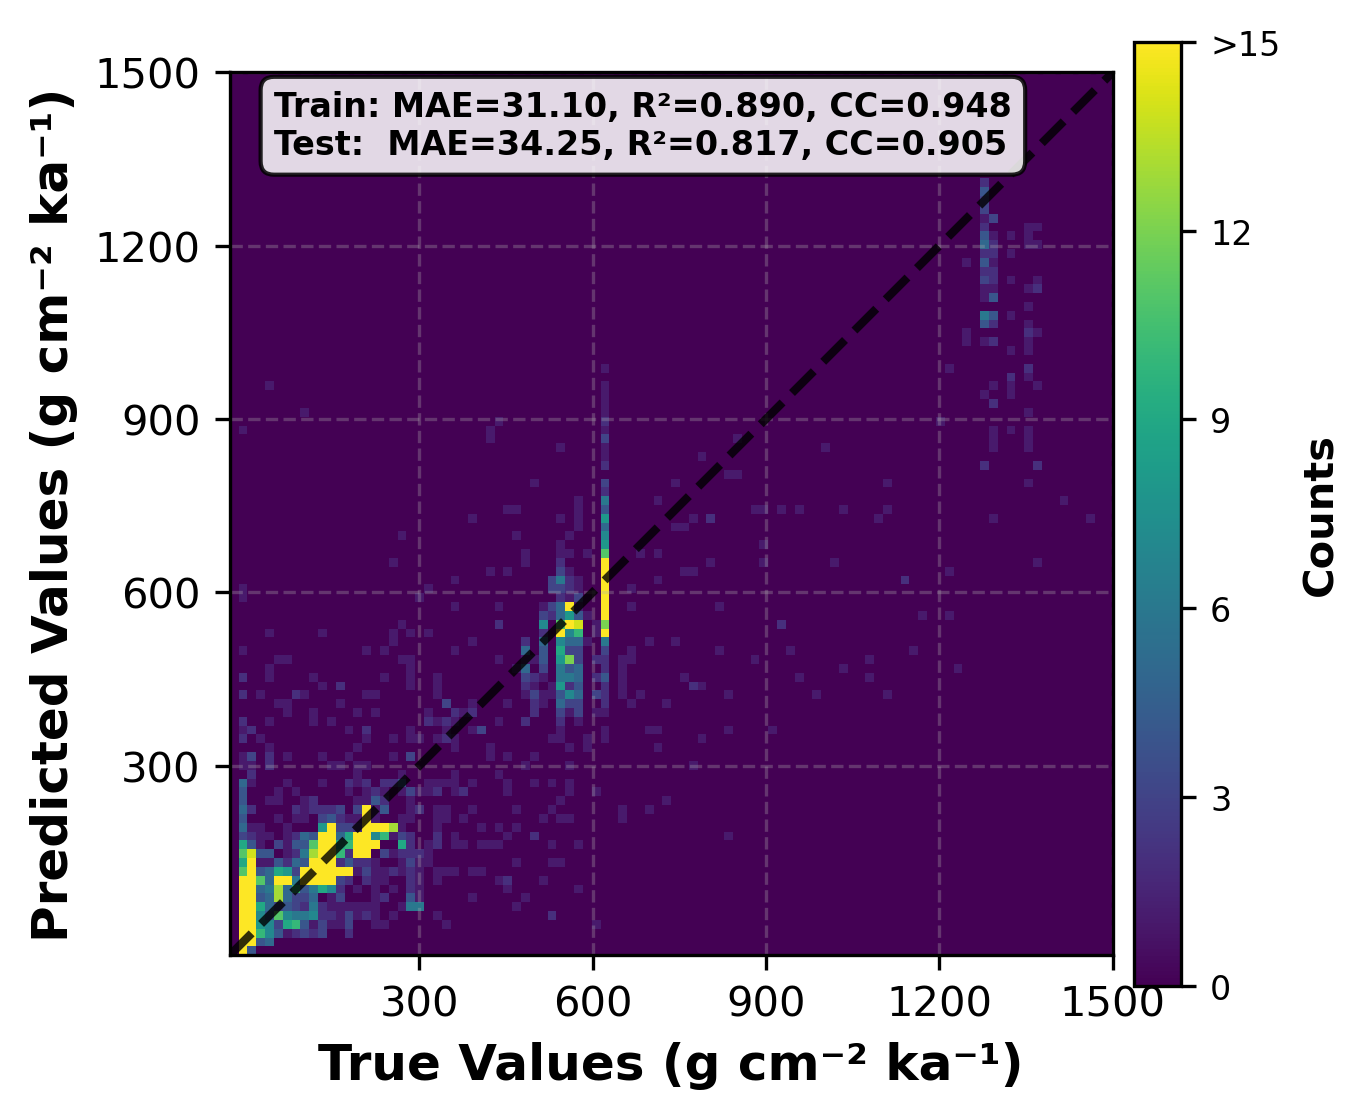

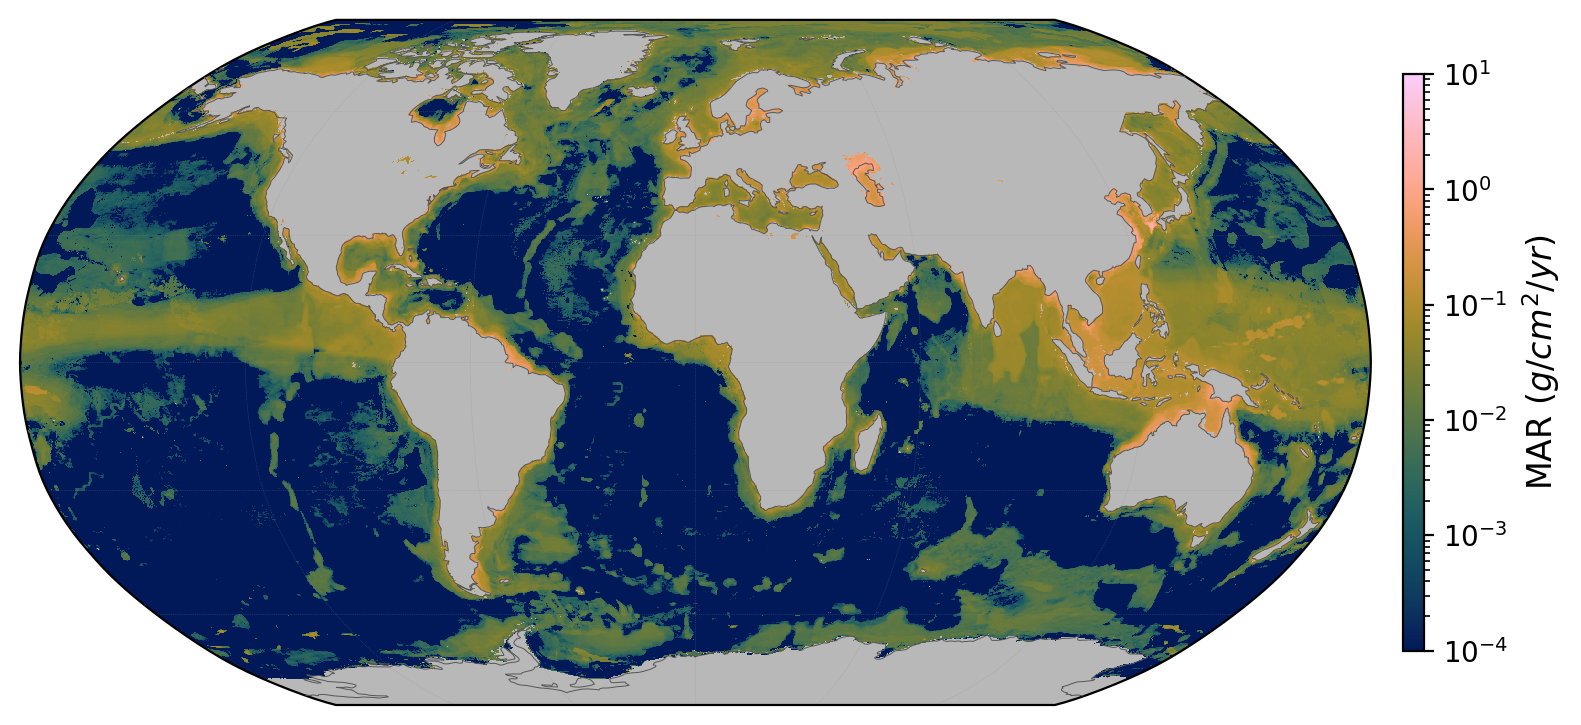

Finished CatBoost (n_estimators=1000)


Outputs: data/output/predictionmaps_SedRate/notebooks_2_trees


In [2]:
run_hyperparameter_search = False  # True → sweep n_estimators grids below
write_maps = True                   # write global MAR maps for each model

# Counts selected by held-out search (lowest test MAE in each family)
selected_configs = {
    "random_forest": 700,
    "xgboost": 1000,
    "catboost": 1000,
}
search_grids = {
    "random_forest": [50, 100, 200, 400, 700, 800, 1000],
    "xgboost": [100, 200, 400, 800, 1000],
    "catboost": [100, 200, 400, 800, 1000],
}

out_dir = PREDICTION_MAPS_DIR / "notebooks_2_trees"
out_dir.mkdir(parents=True, exist_ok=True)
summary_rows = []

for model_type, n_default in selected_configs.items():
    if run_hyperparameter_search:
        # Try several tree counts; keep the one with lowest test MAE
        rows = []
        for n in search_grids[model_type]:
            _, train_mae, test_mae, _, _ = train_tree_based_model(
                train_features, train_labels, test_features, test_labels,
                model_type=model_type, n_estimators=int(n), random_seed=42,
            )
            rows.append({"model": model_type, "n_estimators": int(n), "train_mae": train_mae, "test_mae": test_mae})
            print(f"{model_type} n={n}: train MAE={train_mae:.3f}, test MAE={test_mae:.3f}")
        search_df = pd.DataFrame(rows).sort_values("test_mae")
        search_df.to_csv(out_dir / f"{model_type}_search.csv", index=False)
        n_estimators = int(search_df.iloc[0]["n_estimators"])
        print(f"Best {model_type}: n_estimators={n_estimators}")
    else:
        n_estimators = int(n_default)

    # Fit the selected configuration and score train/test sites
    model, train_mae, test_mae, train_pred, test_pred = train_tree_based_model(
        train_features, train_labels, test_features, test_labels,
        model_type=model_type, n_estimators=n_estimators, random_seed=42,
    )
    tr, te = plot_pred_scatter(
        train_labels, train_pred, test_labels, test_pred,
        f"{model_type} (n={n_estimators})",
    )
    summary_rows.append({
        "model": model_type,
        "n_estimators": n_estimators,
        **{f"test_{k}": v for k, v in te.items()},
    })

    if write_maps:
        # Apply the fitted model to the global ocean feature grid
        predict_global_map_sklearn(
            model,
            world_dir,
            X_mean,
            X_std,
            DATA_RAW / "island_map.npy",
            out_dir / f"prediction_map_MAR_entire_{model_type}_n{n_estimators}_nnimputed.npy",
        )

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(out_dir / "tree_models_test_summary.csv", index=False)
print(summary_df)
print("Outputs:", out_dir)
